# Session 1 lab: Python, Colab and always plotting your data

<p class="lead">
Learn just enough Python to run every notebook in this course, then use it to recreate the lecture's main lesson yourself: summary statistics are not enough, so always plot your data.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/01_why_data_analytics_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## How this lab works

| Part | Level | What you do |
|---|---|---|
| **A. Guided practice** | Core | Follow step by step: Colab, variables, lists, tables, filters, groups and a chart |
| **B. Independent tasks** | Core and Stretch | Use the same skills on a new question: Anscombe's quartet and your own analytical question |
| **C. Challenge** | Challenge | Investigate the Datasaurus Dozen |

**Core** tasks are for everyone and are enough for your portfolio. **Stretch** tasks are for when you finish early. **Challenge** tasks are optional and need more reasoning.

> **How the course uses code**
>
> Every notebook gives you **working code** with explanations. You **read** it, **run** it, then **change** a few lines in the exercises. You will not be asked to write programs from scratch.

**Evidence you keep:** your Anscombe statistics table and plots with a two-sentence lesson, and one workplace decision rewritten as an analytical question.

---

## Part A: Guided practice (Core)

### A1. Google Colab in two minutes

Google Colab is a free website for running Python notebooks. You need a Google account.

1. Go to [colab.research.google.com](https://colab.research.google.com/), or use the **Open in Colab** button above.
2. To open a file you downloaded, choose **File → Upload notebook** and select the `.ipynb` file.
3. A notebook is made of **cells**. Text cells explain; code cells run.
4. Click inside a code cell and press **Shift + Enter** to run it. The result appears underneath.
5. Run cells **from top to bottom**. Later cells use results from earlier ones.

> **If something goes wrong**
>
> Choose **Runtime → Restart session and run all**. This starts again from the top and fixes most problems.

### A2. Values and variables

A **variable** is a name for a value. The `=` sign stores the value under that name.

In [1]:
price = 120
quantity = 3
total = price * quantity
total

360

The last line of a cell is shown as the output. You can also use `print` to show several things.

In [2]:
discount = 0.10
print("Total before discount:", total)
print("Total after discount:", total * (1 - discount))

Total before discount: 360
Total after discount: 324.0


Text goes inside quotes, and a **list** holds several values in square brackets.

In [3]:
segment = "Consumer"
monthly_sales = [120, 95, 140, 180]
print(segment, "sales in four months:", monthly_sales)
print("Total:", sum(monthly_sales))
print("Number of months:", len(monthly_sales))

Consumer sales in four months: [120, 95, 140, 180]
Total: 535
Number of months: 4


> **Your turn:** change the code in the next cell and run it again.

In [4]:
# Change the numbers in the list, then run the cell again.
monthly_sales = [120, 95, 140, 180]
print("Average monthly sales:", sum(monthly_sales) / len(monthly_sales))

Average monthly sales: 133.75


### A3. Tables with pandas

**pandas** is the Python library analysts use for tables. A table in pandas is called a **DataFrame**. We first `import` the library, then build a small made-up table of five orders.

In [5]:
import pandas as pd

orders = pd.DataFrame({
    "order_id": ["A1", "A2", "A3", "A4", "A5"],
    "region": ["North", "South", "North", "East", "South"],
    "sales": [250.0, 120.0, 90.0, 310.0, 180.0],
    "items": [3, 1, 2, 4, 2],
})
orders

,order_id,region,sales,items
0,A1,North,250.0,3
1,A2,South,120.0,1
2,A3,North,90.0,2
3,A4,East,310.0,4
4,A5,South,180.0,2


Each **row** is one order. Each **column** has a name. Useful first checks:

In [6]:
print("Rows and columns:", orders.shape)
print(orders.dtypes)

Rows and columns: (5, 4)
order_id     object
region       object
sales       float64
items         int64
dtype: object


`dtypes` shows each column's type: `object` means text, `int64` whole numbers, `float64` decimals.

### A4. Select, filter, add up, count

**Select one column** with its name in square brackets:

In [7]:
orders["sales"]

0    250.0
1    120.0
2     90.0
3    310.0
4    180.0
Name: sales, dtype: float64

**Add up** or **average** a column:

In [8]:
print("Total sales:", orders["sales"].sum())
print("Average sales per order:", orders["sales"].mean())

Total sales: 950.0
Average sales per order: 190.0


**Filter rows** with a condition. This keeps only orders from the North region:

In [9]:
north = orders[orders["region"] == "North"]
north

,order_id,region,sales,items
0,A1,North,250.0,3
2,A3,North,90.0,2


**Count** how many rows, and how many **different** values a column has:

In [10]:
print("Number of orders:", len(orders))
print("Number of different regions:", orders["region"].nunique())

Number of orders: 5
Number of different regions: 3


> **Your turn:** change the code in the next cell and run it again.

In [11]:
# Change "North" to "South" and run again. How many South orders are there,
# and what are their total sales?
selected = orders[orders["region"] == "North"]
print(len(selected), "orders, total sales", selected["sales"].sum())

2 orders, total sales 340.0


### A5. Group and summarise

`groupby` splits the table into groups and summarises each one. Here: total sales for each region.

In [12]:
sales_by_region = orders.groupby("region")["sales"].sum()
sales_by_region

region
East     310.0
North    340.0
South    300.0
Name: sales, dtype: float64

`agg` computes **several** summaries for each group at once. Each line inside it reads: *new column name = (column to use, summary to compute)*. You will use this pattern in Part B.

In [13]:
orders.groupby("region").agg(
    orders=("order_id", "count"),
    total_sales=("sales", "sum"),
    average_sales=("sales", "mean"),
)

,orders,total_sales,average_sales
region,,,
East,1,310.0,310.0
North,2,340.0,170.0
South,2,300.0,150.0


### A6. Your first chart

pandas can draw a chart directly from a summary. `kind="barh"` makes horizontal bars.

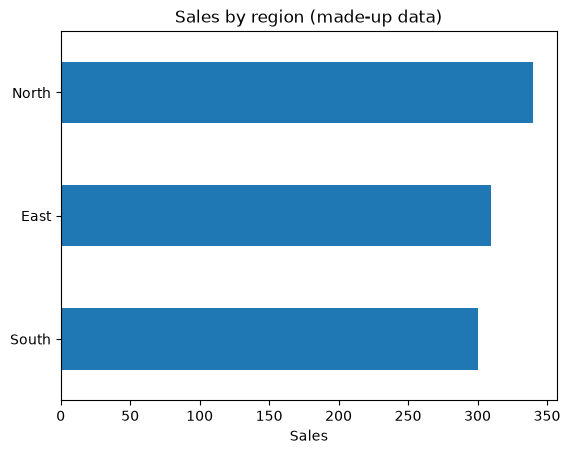

In [14]:
import matplotlib.pyplot as plt

sales_by_region.sort_values().plot(kind="barh", title="Sales by region (made-up data)")
plt.xlabel("Sales")
plt.ylabel("")
plt.show()

> **Your turn:** change the code in the next cell and run it again.

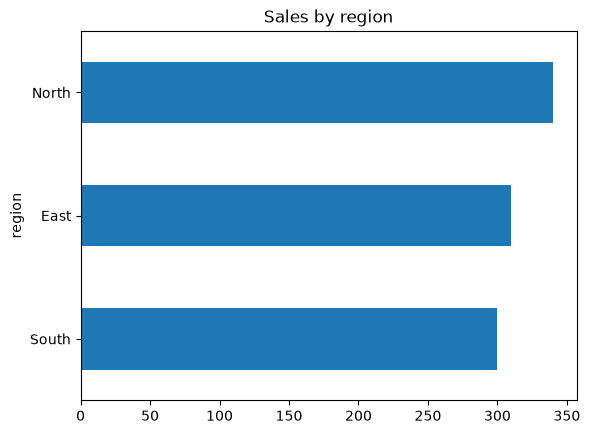

In [15]:
# Change "sales" to "items" to chart the number of items per region instead.
# Then change the title to match.
orders.groupby("region")["sales"].sum().sort_values().plot(kind="barh", title="Sales by region")
plt.show()

A **scatter plot** shows two numbers for each row: one along the bottom, one up the side. You will use it in Part B.

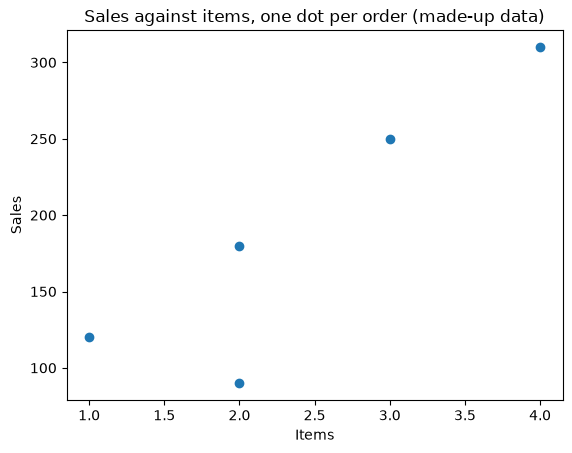

In [16]:
plt.scatter(orders["items"], orders["sales"])
plt.title("Sales against items, one dot per order (made-up data)")
plt.xlabel("Items")
plt.ylabel("Sales")
plt.show()

---

## Part B: Independent tasks

Now use the same skills on the lecture's main example. The code works as given; your job is to change it and explain what you find.

### B1. Anscombe's statistics (Core)

Run the cell below. It builds Anscombe's four datasets in one table, with a `set` column saying which dataset each point belongs to.

In [17]:
import pandas as pd

# Anscombe's quartet (1973): four small datasets, eleven points each.
x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = pd.concat([
    pd.DataFrame({"set": "I",   "x": x, "y": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]}),
    pd.DataFrame({"set": "II",  "x": x, "y": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]}),
    pd.DataFrame({"set": "III", "x": x, "y": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]}),
    pd.DataFrame({"set": "IV",  "x": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
                  "y": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]}),
], ignore_index=True)

print("Rows, columns:", anscombe.shape)
anscombe.head()

Rows, columns: (44, 3)


,set,x,y
0,I,10,8.04
1,I,8,6.95
2,I,13,7.58
3,I,9,8.81
4,I,11,8.33


> **Your turn:** change the code in the next cell and run it again.

In [18]:
# The code computes ONE statistic for each set: the mean of x.
# 1. Add a line for the mean of y:            mean_y=("y", "mean"),
# 2. Add the standard deviation of x and y:   sd_x=("x", "std"),  sd_y=("y", "std"),
# 3. Run it. Which statistics are the same in all four sets?
anscombe.groupby("set").agg(
    mean_x=("x", "mean"),
).round(2)

,mean_x
set,
I,9.0
II,9.0
III,9.0
IV,9.0


The correlation measures how closely the points follow a straight line (from −1 to +1). The next cell computes it for each set.

In [19]:
anscombe.groupby("set")[["x", "y"]].apply(lambda d: d["x"].corr(d["y"])).round(3)

set
I      0.816
II     0.816
III    0.816
IV     0.817
dtype: float64

### B2. Plot all four (Core)

The cell below draws a scatter plot for **one** set.

> **Your turn:** change the code in the next cell and run it again.

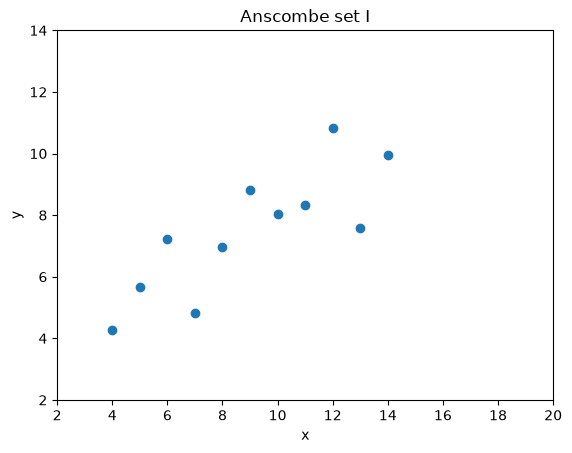

In [20]:
# 1. Change "I" to "II", "III" and "IV" in turn, and look at each picture.
# 2. Change the title so it names the set you are showing.
one_set = anscombe[anscombe["set"] == "I"]
plt.scatter(one_set["x"], one_set["y"])
plt.title("Anscombe set I")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(2, 20)
plt.ylim(2, 14)
plt.show()

Looking at one set at a time makes comparison hard. This version draws all four side by side with the **same axes**, so you can compare them directly.

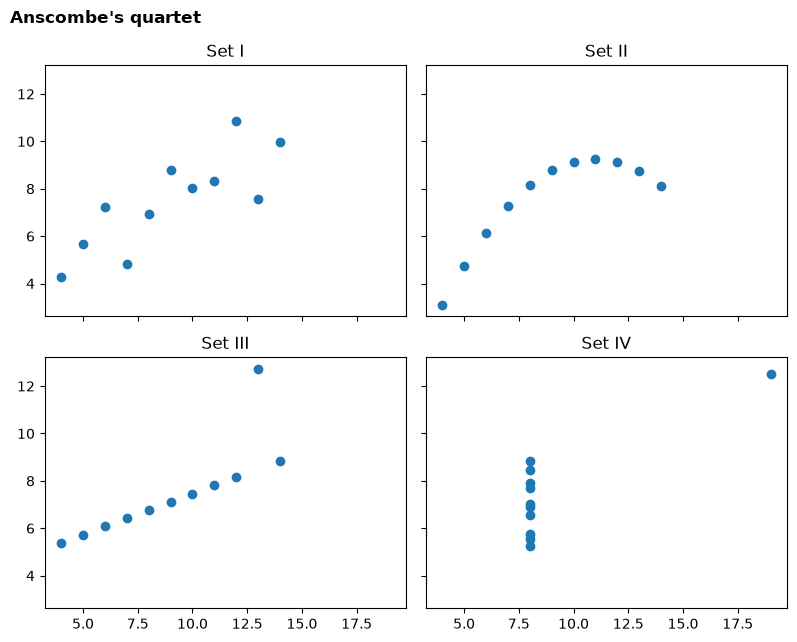

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6.5), sharex=True, sharey=True)
for ax, (name, points) in zip(axes.flat, anscombe.groupby("set")):
    ax.scatter(points["x"], points["y"])
    ax.set_title(f"Set {name}")
fig.suptitle("Anscombe's quartet", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

> **Write it down (Core evidence)**
>
> Double-click this cell and replace the text below with **two sentences**: what the statistics said, and what the plots showed that the statistics did not.
>
> *Sentence 1:* …
>
> *Sentence 2:* …

### B3. From decision to question (Core)

Think of one decision at your own workplace, or one you have seen, that was made on gut feeling. Rewrite it as an analytical question. Edit the text in the cell below, then run it to print your question as a small table.

In [22]:
# Replace each text in quotes with your own words, then run the cell.
my_question = {
    "Decision":   "Which branch gets the extra staff member next quarter",
    "Population": "All customer visits recorded at our five branches",
    "Period":     "January to June this year",
    "Measure":    "Average visits per staff member per day, by branch",
}
pd.Series(my_question, name="My analytical question")

Decision      Which branch gets the extra staff member next ...
Population    All customer visits recorded at our five branches
Period                                January to June this year
Measure       Average visits per staff member per day, by br...
Name: My analytical question, dtype: object

> **Check your question**
>
> 1. Would two different analysts compute the **same number** from your measure?
> 2. Does the population say which records are **left out**?
> 3. Would the answer actually change the decision?
>
> Then write your question as one sentence, like the example in the lecture.

### B4. Add the trend lines (Stretch)

`np.polyfit(x, y, 1)` finds the straight line that best fits the points and returns its **slope** and **intercept**.

> **Your turn:** change the code in the next cell and run it again.

Set   I: y = 3.00 + 0.500 x
Set  II: y = 3.00 + 0.500 x
Set III: y = 3.00 + 0.500 x
Set  IV: y = 3.00 + 0.500 x


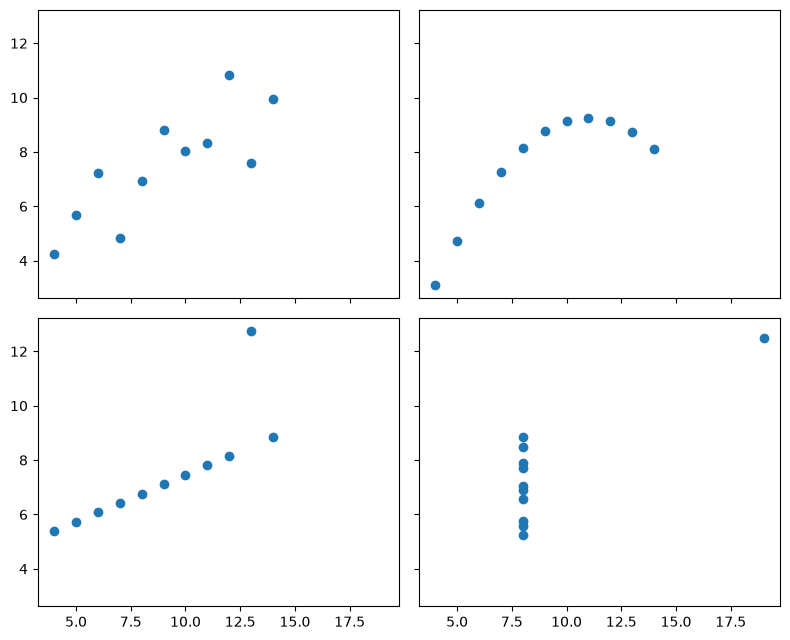

In [23]:
import numpy as np

# 1. Run the cell: it prints the best-fit line for every set.
# 2. Then remove the # from the two plotting lines to draw each line on its panel.
fig, axes = plt.subplots(2, 2, figsize=(8, 6.5), sharex=True, sharey=True)
line_x = np.array([2, 20])
for ax, (name, points) in zip(axes.flat, anscombe.groupby("set")):
    slope, intercept = np.polyfit(points["x"], points["y"], 1)
    print(f"Set {name:>3}: y = {intercept:.2f} + {slope:.3f} x")
    ax.scatter(points["x"], points["y"])
    # ax.plot(line_x, intercept + slope * line_x, color="#d95f02")
    # ax.set_title(f"Set {name}: y = {intercept:.2f} + {slope:.2f} x")
fig.tight_layout()
plt.show()

Which sets does the straight line describe well, and which does it describe badly?

### B5. One point can change everything (Stretch)

In set III, one point sits far above the others. What happens to the correlation if we leave it out?

> **Your turn:** change the code in the next cell and run it again.

In [24]:
# 1. Run the cell: it compares set III with and without its largest y value.
# 2. Change "III" to "IV" and run again. What happens, and why?
chosen = anscombe[anscombe["set"] == "III"]
without_top = chosen[chosen["y"] != chosen["y"].max()]

print("Correlation, all points:      ", round(chosen["x"].corr(chosen["y"]), 3))
print("Correlation, top point removed:", round(without_top["x"].corr(without_top["y"]), 3))

Correlation, all points:       0.816
Correlation, top point removed: 1.0


> **Think before you delete**
>
> Removing a point changed the answer. That does **not** mean you should remove it. First find out *why* it is unusual: a data-entry error, a special event, or a real customer? Session 3 covers how to decide.

---

## Part C: Challenge — the Datasaurus Dozen

Thirteen datasets, one of them a dinosaur. Can **any** summary statistic tell them apart, or do you need a chart?

The next cell downloads the data from a fixed public address and checks its fingerprint.

In [25]:
import hashlib
import io
import urllib.request

import pandas as pd

# The Datasaurus Dozen (Matejka and Fitzmaurice, 2017), from the open-source
# datasauRus package (MIT licence). The link points to one fixed version, and the
# fingerprint check confirms we got exactly that file.
DATASAURUS_URL = ("https://raw.githubusercontent.com/jumpingrivers/datasauRus/"
                  "94f3c3a82660e256b84f70961f50dc0e216757de/inst/extdata/DatasaurusDozen-Long.tsv")
DATASAURUS_SHA256 = "c8c4792c3ed15238ba07dad6ab778adc79d72e3e1324ead4d8c1ae52849780f8"

file_bytes = urllib.request.urlopen(DATASAURUS_URL).read()
assert hashlib.sha256(file_bytes).hexdigest() == DATASAURUS_SHA256, "Unexpected file: ask your instructor."
dozen = pd.read_csv(io.BytesIO(file_bytes), sep="\t")

print("Rows, columns:", dozen.shape)
print("Datasets:", dozen["dataset"].nunique())
dozen.head()

Rows, columns: (1846, 3)
Datasets: 13


,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


> **Your turn:** change the code in the next cell and run it again.

In [26]:
# 1. Run the cell: it shows the mean of x and y for every dataset.
# 2. Add the standard deviations:  sd_x=("x", "std"), sd_y=("y", "std"),
# 3. Then try other statistics:    median_x=("x", "median"), min_y=("y", "min"), max_y=("y", "max"),
# 4. Look for a statistic whose values clearly differ between datasets.
dozen.groupby("dataset").agg(
    mean_x=("x", "mean"),
    mean_y=("y", "mean"),
).round(2)

,mean_x,mean_y
dataset,,
away,54.27,47.83
bullseye,54.27,47.83
circle,54.27,47.84
dino,54.26,47.83
dots,54.26,47.84
h_lines,54.26,47.83
high_lines,54.27,47.84
slant_down,54.27,47.84
slant_up,54.27,47.83


Now draw one small chart per dataset.

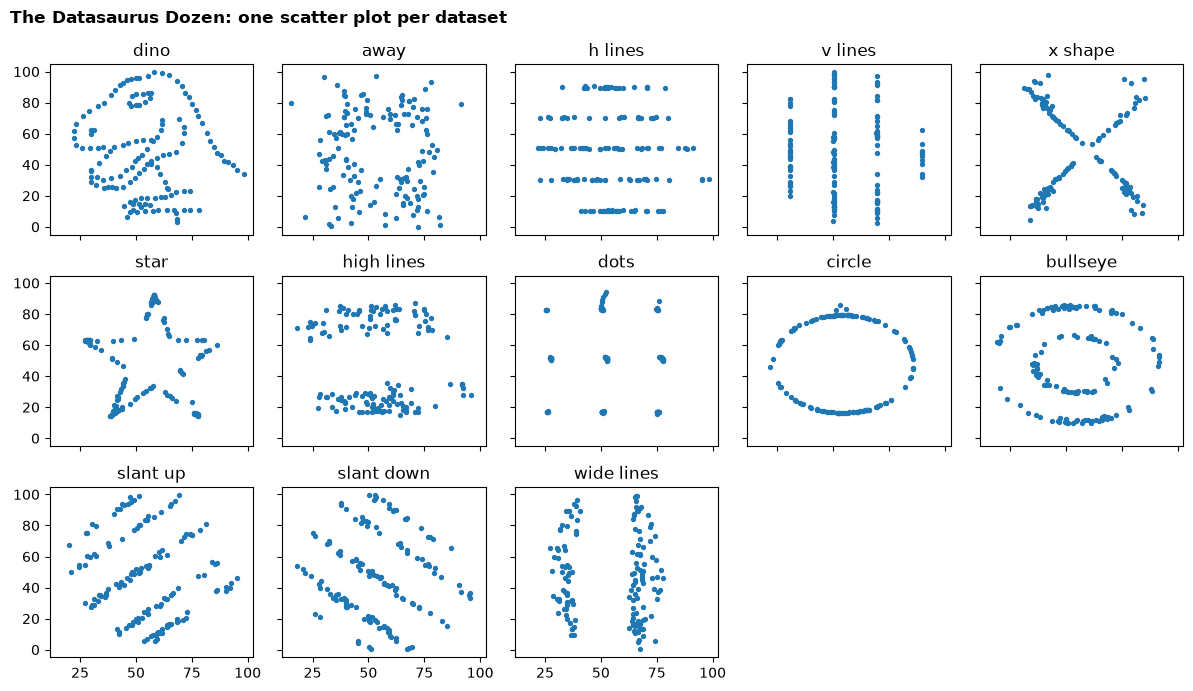

In [27]:
import matplotlib.pyplot as plt

names = dozen["dataset"].unique()
fig, axes = plt.subplots(3, 5, figsize=(12, 7), sharex=True, sharey=True)
for ax in axes.flat:
    ax.set_visible(False)
for ax, name in zip(axes.flat, names):
    points = dozen[dozen["dataset"] == name]
    ax.set_visible(True)
    ax.scatter(points["x"], points["y"], s=8)
    ax.set_title(name.replace("_", " "))
fig.suptitle("The Datasaurus Dozen: one scatter plot per dataset", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

> **Challenge questions**
>
> 1. Which statistics were almost identical for all thirteen datasets?
> 2. Did you find any statistic that differs? Does it tell you the **shape**, or only that something is different?
> 3. `dozen[dozen["dataset"] == "dino"].describe()` shows eight statistics for one dataset. Compare `dino` with `star` this way. What do you conclude?
> 4. A manager asks you to "just send the averages" for a new dataset. Write two sentences explaining why you will send a chart too.

In [28]:
# Space for your Challenge work. Example to start from:
dozen[dozen["dataset"] == "dino"].describe().round(2)

,x,y
count,142.00,142.00
mean,54.26,47.83
std,16.77,26.94
min,22.31,2.95
25%,44.10,25.29
50%,53.33,46.03
75%,64.74,68.53
max,98.21,99.49


---

## Quick reference

| You want to… | Code |
|---|---|
| See the first rows | `df.head()` |
| Size of the table | `df.shape` |
| Column types | `df.dtypes` |
| One column | `df["sales"]` |
| Filter rows | `df[df["region"] == "North"]` |
| Total / average | `df["sales"].sum()` / `df["sales"].mean()` |
| Count rows / different values | `len(df)` / `df["region"].nunique()` |
| Total per group | `df.groupby("region")["sales"].sum()` |
| Several summaries per group | `df.groupby("region").agg(total=("sales", "sum"))` |
| Correlation of two columns | `df["x"].corr(df["y"])` |
| Bar chart | `series.plot(kind="barh")` |
| Scatter plot | `plt.scatter(df["x"], df["y"])` |

---

## Exit ticket

1. What does pressing **Shift + Enter** do?
2. What is the difference between `len(df)` and `df["region"].nunique()`?
3. Which code gives total sales for each region?
4. In one sentence: why did we plot Anscombe's sets after computing their statistics?

## Evidence to keep

- [ ] Your Anscombe statistics table (B1) and the four plots (B2)
- [ ] Your two-sentence lesson (B2)
- [ ] Your analytical question with decision, population, period and measure (B3)

Next: [Session 2 lecture: Data, grain and the DataFrame](02_data_and_grain_lecture.md), where you load a real retail dataset.